# Vitaliza · Análise Exploratória de Dados (EDA)
**Grupo 08 · Módulo 2 · Artefato de Tecnologia da semana 5**

A Vitaliza é um app de assinatura para quem treina. Este caderno conta a história analítica da saída de assinantes (churn) em quatro passos:

1. **Os dados e a limpeza:** o que chegou no data room, o que estava errado e o que foi feito.
2. **O tamanho do problema:** o churn mês a mês e por plano.
3. **Padrões e correlações com a saída:** quem sai em 60 dias se comporta diferente de quem fica?
4. **A base da segmentação:** os quatro segmentos e a saída em cada um.

**Regras seguidas em todo o caderno**
- Data de corte: 30/09/2026. Nada posterior ao corte entra nas variáveis.
- Horários em UTC (terminados em `Z`) convertidos para Brasília.
- Contas de teste (e-mail `@vitaliza.com.br`) ficam fora.
- `dados/brutos/` é só leitura: o SHA-256 dos arquivos é conferido no início e no fim.
- Cada filtro e cada junção mostra as linhas antes e depois.

As tabelas tratadas em `dados/processados/` são geradas pelos scripts do grupo em `src/` (a ordem está no `README` do artefato, em `saidas/eda/LEIA-ME.md`). Os gráficos deste caderno são gravados em `saidas/eda/` e alimentam o *Customer Segmentation Report*.

In [1]:
import hashlib
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from utils import BRUTOS, PROCESSADOS, contas_de_teste, mostrar, para_brasilia
import eda_graficos as eg

eg.estilo()
pd.set_option("display.max_columns", 30, "display.width", 160)
CORTE = pd.Timestamp("2026-09-30 23:59:59")


def sha256(caminho: Path) -> str:
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()


def mostrar_grafico(fig, nome):
    destino = eg.salvar(fig, nome)
    plt.close(fig)
    display(Image(filename=str(destino), width=900))
    print(f"gravado em saidas/eda/{nome}")


arquivos_brutos = sorted(p for p in BRUTOS.iterdir() if p.is_file())
HASH_ANTES = {p.name: sha256(p) for p in arquivos_brutos}
print(f"{len(HASH_ANTES)} arquivos brutos com SHA-256 registrado")

12 arquivos brutos com SHA-256 registrado


## 1. Os dados e a limpeza

### 1.1 O que chegou no data room
Doze arquivos tabulares e duas pastas de imagens (heatmaps de rotas). A tabela compara as linhas de cada arquivo com o que o dicionário de dados promete.

In [2]:
ESPERADO = {
    "usuarios.csv": 64_948, "assinaturas.csv": 32_643, "eventos_assinatura.csv": 275_565, "pagamentos.csv": 165_548,
    "uso_mensal.csv": 591_662, "atividades.parquet": 1_254_475, "onboarding.csv": 63_929, "pesquisa_saida.csv": 643,
    "feed_posts.csv": 119_309, "tickets_suporte.csv": 4_422, "amizades.csv": 113_480, "campanha_ago26.csv": 14_120,
}
linhas = []
for nome, esperado in ESPERADO.items():
    caminho = BRUTOS / nome
    if caminho.suffix == ".parquet":
        meta = pq.ParquetFile(caminho).metadata
        n, colunas = meta.num_rows, meta.num_columns
    else:
        df = pd.read_csv(caminho, dtype=str)
        n, colunas = len(df), df.shape[1]
    linhas.append([nome, n, esperado, "OK" if n == esperado else "DIVERGE", colunas, round(caminho.stat().st_size / 2**20, 1)])
inventario = pd.DataFrame(linhas, columns=["arquivo", "linhas", "esperado (dicionário)", "confere", "colunas", "MB"])
heat = {d.name: len(list(d.glob("*.png"))) for d in sorted((BRUTOS / "heatmaps_90d").iterdir())}
print("heatmaps_90d:", ", ".join(f"{k}: {v:,} imagens".replace(",", ".") for k, v in heat.items()))
inventario

heatmaps_90d: 2026-07-31: 12.426 imagens, 2026-09-30: 13.047 imagens


,arquivo,linhas,esperado (dicionário),confere,colunas,MB
0,usuarios.csv,64948,64948,OK,12,7.5
1,assinaturas.csv,32643,32643,OK,9,2.4
2,eventos_assinatura.csv,275565,275565,OK,6,16.9
3,pagamentos.csv,165548,165548,OK,7,11.0
4,uso_mensal.csv,591662,591662,OK,8,18.3
5,atividades.parquet,1254475,1254475,OK,11,18.3
6,onboarding.csv,63929,63929,OK,7,5.5
7,pesquisa_saida.csv,643,643,OK,5,0.0
8,feed_posts.csv,119309,119309,OK,5,8.5
9,tickets_suporte.csv,4422,4422,OK,8,0.5


### 1.2 Problemas de qualidade encontrados (recontados aqui, direto do bruto)
Cada problema foi medido nas cinco dimensões de qualidade: completude, validade, consistência, unicidade e temporalidade.

In [3]:
usuarios = pd.read_csv(BRUTOS / "usuarios.csv", dtype=str)
teste = contas_de_teste()
ativ = pd.read_parquet(BRUTOS / "atividades.parquet", columns=["user_id", "tipo", "duracao_min", "distancia_km", "origem", "gps_ok"])
onb = pd.read_csv(BRUTOS / "onboarding.csv", dtype=str)
uso = pd.read_csv(BRUTOS / "uso_mensal.csv", dtype={"mes": str})
ev = pd.read_csv(BRUTOS / "eventos_assinatura.csv", dtype=str, usecols=["data_hora"])

ingles = ativ["tipo"].isin(["run", "walk", "ride", "strength"])
uso["ano"] = uso["mes"].str[:4]
zeros = uso.assign(zero=uso["minutos"].eq(0)).groupby("ano")["zero"].mean()
problemas = pd.DataFrame([
    ["completude", "onboarding.csv", "`nivel` vazio (campo não opcional)", onb["nivel"].isna().sum()],
    ["completude", "onboarding.csv", "`dias_por_semana` vazio (campo não opcional)", onb["dias_por_semana"].isna().sum()],
    ["validade", "atividades.parquet", "distância acima de 200 km (máx. %s km)" % eg.br(ativ["distancia_km"].max(), 2), (ativ["distancia_km"] > 200).sum()],
    ["validade", "atividades.parquet", "duração zero", (ativ["duracao_min"] <= 0).sum()],
    ["consistência", "atividades.parquet", "`tipo` em inglês (run, walk, ride, strength), só da origem app", ingles.sum()],
    ["consistência", "usuarios.csv", "grafias diferentes de `sexo`", usuarios["sexo"].nunique()],
    ["unicidade", "usuarios.csv", "contas de teste (@vitaliza.com.br)", len(teste)],
    ["temporalidade", "eventos_assinatura.csv", "horários em UTC (com Z) misturados com Brasília", ev["data_hora"].str.endswith("Z", na=False).sum()],
    ["temporalidade", "uso_mensal.csv", "mês sem treino: %s das linhas zeradas em 2026, nenhuma em 2025" % f"{100 * zeros.get('2026', 0):.1f}%".replace(".", ","), uso.loc[uso["ano"] == "2026", "minutos"].eq(0).sum()],
], columns=["dimensão", "arquivo", "problema", "linhas"])
print("origem dos tipos em inglês:", ativ.loc[ingles, "origem"].value_counts().to_dict())
problemas

origem dos tipos em inglês: {'app': 376930}


,dimensão,arquivo,problema,linhas
0,completude,onboarding.csv,`nivel` vazio (campo não opcional),4513
1,completude,onboarding.csv,`dias_por_semana` vazio (campo não opcional),6368
2,validade,atividades.parquet,"distância acima de 200 km (máx. 10.012,75 km)",951
3,validade,atividades.parquet,duração zero,3649
4,consistência,atividades.parquet,"`tipo` em inglês (run, walk, ride, strength), ...",376930
5,consistência,usuarios.csv,grafias diferentes de `sexo`,6
6,unicidade,usuarios.csv,contas de teste (@vitaliza.com.br),60
7,temporalidade,eventos_assinatura.csv,horários em UTC (com Z) misturados com Brasília,186323
8,temporalidade,uso_mensal.csv,"mês sem treino: 69,1% das linhas zeradas em 20...",303735


Um problema que não aparece em contagem simples: **9.383 treinos chegaram em dobro**, uma vez pelo app e outra pelo relógio. O Garmin grava o início em UTC (3 horas à frente); sem corrigir o fuso, só metade dos pares aparece (`saidas/unicidade_atividades.md`).

### 1.3 Decisões de limpeza
Toda escolha de corrigir, remover ou marcar está no `decisoes.md`, com motivo e efeito na contagem. O resumo:

In [4]:
texto = (RAIZ / "decisoes.md").read_text(encoding="utf-8").splitlines()
reg = [l.split("|") for l in texto if l.startswith("| ") and l.split("|")[1].strip().isdigit()]
dec = pd.DataFrame({"n": [int(r[1]) for r in reg], "arquivo": [r[3].strip() for r in reg], "decisao": [r[5].strip().lower() for r in reg]})
dec["tipo"] = np.select([dec["decisao"].str.startswith("remov"), dec["decisao"].str.startswith("corrig"), dec["decisao"].str.startswith("marc")],
                        ["remover", "corrigir", "marcar"], "outro (definição/método)")
print(f"{len(dec)} decisões registradas")
dec["tipo"].value_counts().rename("decisões").to_frame()

47 decisões registradas


,decisões
tipo,
outro (definição/método),18
marcar,14
corrigir,11
remover,4


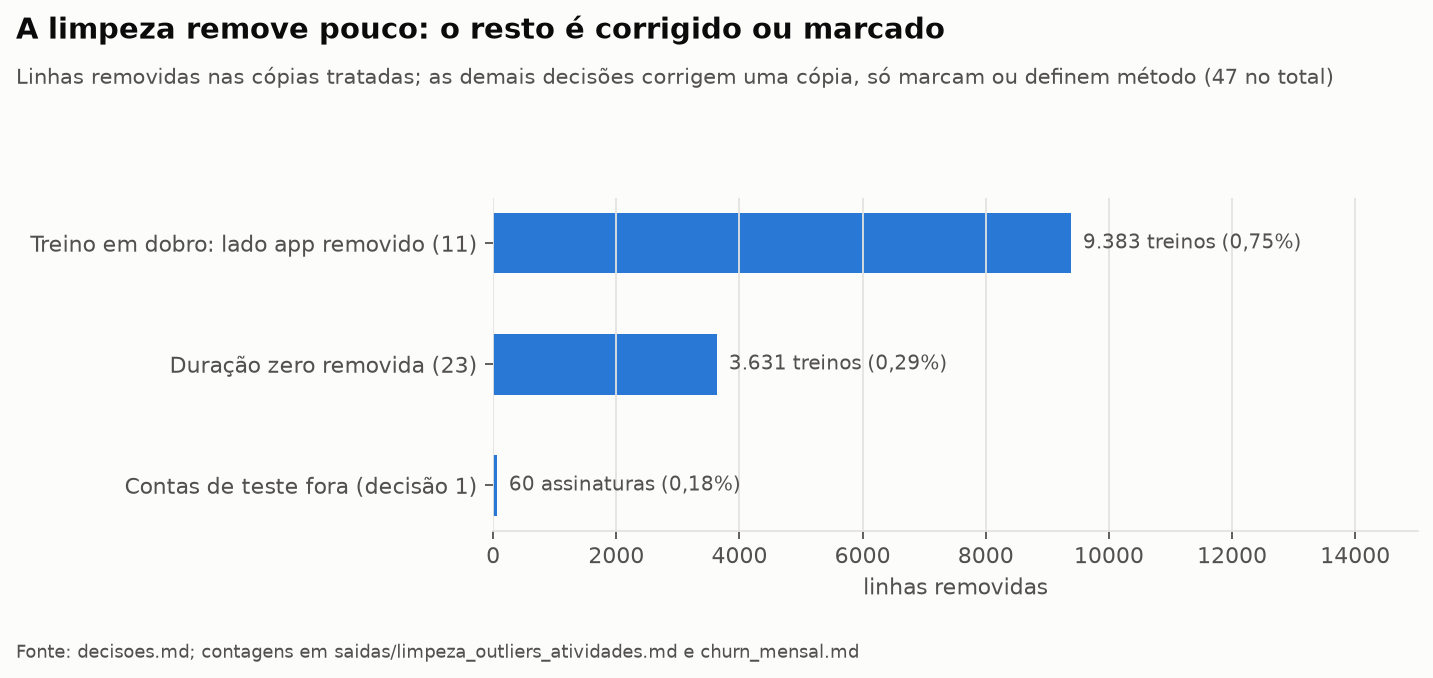

gravado em saidas/eda/01_limpeza_linhas_removidas.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
efeitos = pd.DataFrame([
    ["Contas de teste fora (decisão 1)", 32_643, 32_583, "assinaturas"],
    ["Duração zero removida (23)", 1_245_092, 1_241_461, "treinos"],
    ["Treino em dobro: lado app removido (11)", 1_254_475, 1_245_092, "treinos"],
])
efeitos["removidas"] = efeitos[1] - efeitos[2]
efeitos = efeitos.sort_values("removidas")
ax.barh(efeitos[0], efeitos["removidas"], color=eg.AZUL, height=0.5)
for y, (v, base, unid) in enumerate(zip(efeitos["removidas"], efeitos[1], efeitos[3])):
    ax.text(v, y, f"  {eg.br(v, 0)} {unid} ({eg.br(100 * v / base, 2)}%)", va="center", color=eg.TEXTO_2, fontsize=9)
ax.set_xlim(0, efeitos["removidas"].max() * 1.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("linhas removidas")
eg.titulo(fig, "A limpeza remove pouco: o resto é corrigido ou marcado", "Linhas removidas nas cópias tratadas; as demais decisões corrigem uma cópia, só marcam ou definem método (47 no total)")
eg.fonte(fig, "Fonte: decisoes.md; contagens em saidas/limpeza_outliers_atividades.md e churn_mensal.md")
eg.ajustar(fig)
mostrar_grafico(fig, "01_limpeza_linhas_removidas.png")

## 2. O tamanho do problema

### 2.1 Churn mensal
Definição oficial do case: **perdas no mês ÷ ativos no início do mês**. A série vem de `src/churn_mensal.py` e reproduz os números de referência (abril/2026: 1.154 ÷ 14.237 = 8,1%; 14.753 ativos em 30/09).

média 2025: 5.6% · média jan–set/2026: 6.6% · abril/2026: 1154 ÷ 14237 = 8.1%


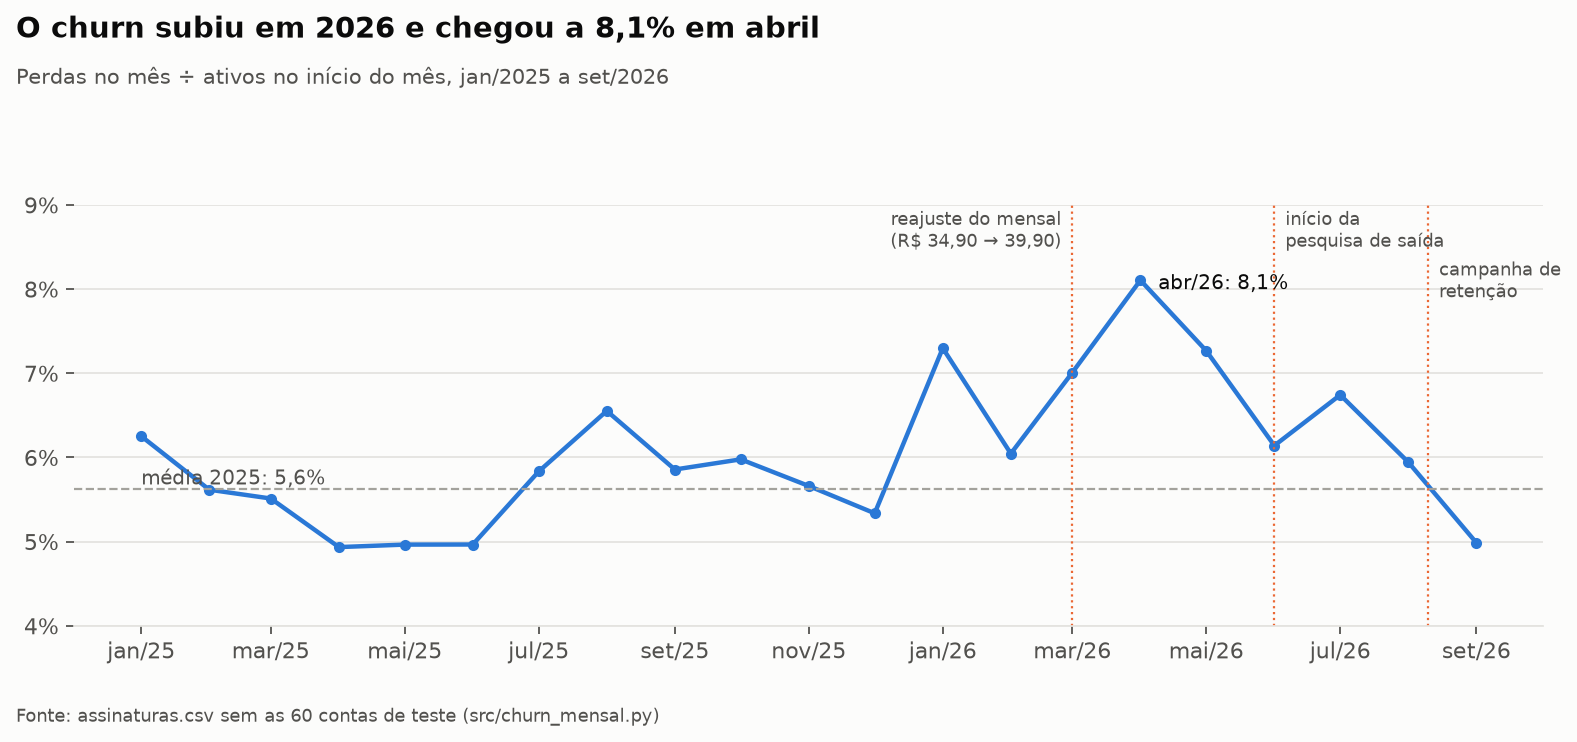

gravado em saidas/eda/02_churn_mensal.png


In [6]:
churn = pd.read_csv(PROCESSADOS / "churn_mensal.csv")
churn["mes_d"] = pd.PeriodIndex(churn["mes"], freq="M").to_timestamp()
churn["taxa"] = churn["perdas"] / churn["ativos"]
media25 = churn.loc[churn["mes"].str.startswith("2025"), "taxa"].mean()
media26 = churn.loc[churn["mes"].str.startswith("2026"), "taxa"].mean()
abril = churn.set_index("mes").loc["2026-04"]
print(f"média 2025: {media25:.1%} · média jan–set/2026: {media26:.1%} · abril/2026: {abril['perdas']:.0f} ÷ {abril['ativos']:.0f} = {abril['taxa']:.1%}")

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(churn["mes_d"], churn["taxa"], color=eg.AZUL, marker="o", markersize=4)
ax.axhline(media25, color=eg.NEUTRO, linestyle="--", linewidth=1)
ax.text(churn["mes_d"].iloc[0], media25, f"média 2025: {eg.br(100 * media25)}%", va="bottom", color=eg.TEXTO_2, fontsize=9)
eventos = [("2026-03-01", "reajuste do mensal\n(R$ 34,90 → 39,90)", 0.0895, "right"), ("2026-06-01", "início da\npesquisa de saída", 0.0895, "left"),
           ("2026-08-10", "campanha de\nretenção", 0.0835, "left")]
for data, rotulo, y, lado in eventos:
    ax.axvline(pd.Timestamp(data), color=eg.LARANJA, linewidth=1, linestyle=":")
    ax.text(pd.Timestamp(data) + pd.Timedelta(days=-5 if lado == "right" else 5), y, rotulo, color=eg.TEXTO_2, fontsize=8, va="top", ha=lado)
ax.annotate(f"abr/26: {eg.br(100 * abril['taxa'])}%", (abril["mes_d"], abril["taxa"]), xytext=(8, -4), textcoords="offset points", fontsize=9, color=eg.TEXTO)
ax.yaxis.set_major_formatter(eg.pct())
ax.set_ylim(0.04, 0.09)
ax.grid(axis="x", visible=False)
eg.eixo_meses(ax)
eg.titulo(fig, "O churn subiu em 2026 e chegou a 8,1% em abril", "Perdas no mês ÷ ativos no início do mês, jan/2025 a set/2026")
eg.fonte(fig, "Fonte: assinaturas.csv sem as 60 contas de teste (src/churn_mensal.py)")
eg.ajustar(fig)
mostrar_grafico(fig, "02_churn_mensal.png")

### 2.2 Churn mensal por plano
O reajuste de 01/03/2026 só atingiu o plano mensal. Se ele explica a subida, o churn do mensal deve subir e o do anual, não. Mesma definição da série oficial, separada pelo plano (o plano não muda ao longo da assinatura nos eventos, então o retrato de `assinaturas.csv` serve aqui).

[linhas] assinaturas sem cortesia/teste: 32.583 (antes 32.643, diferença -60)
soma mensal + anual = série oficial: OK
média mar/25–fev/26: {'anual': 2.9, 'mensal': 9.0} · média mar–mai/26: {'anual': 3.0, 'mensal': 13.0}


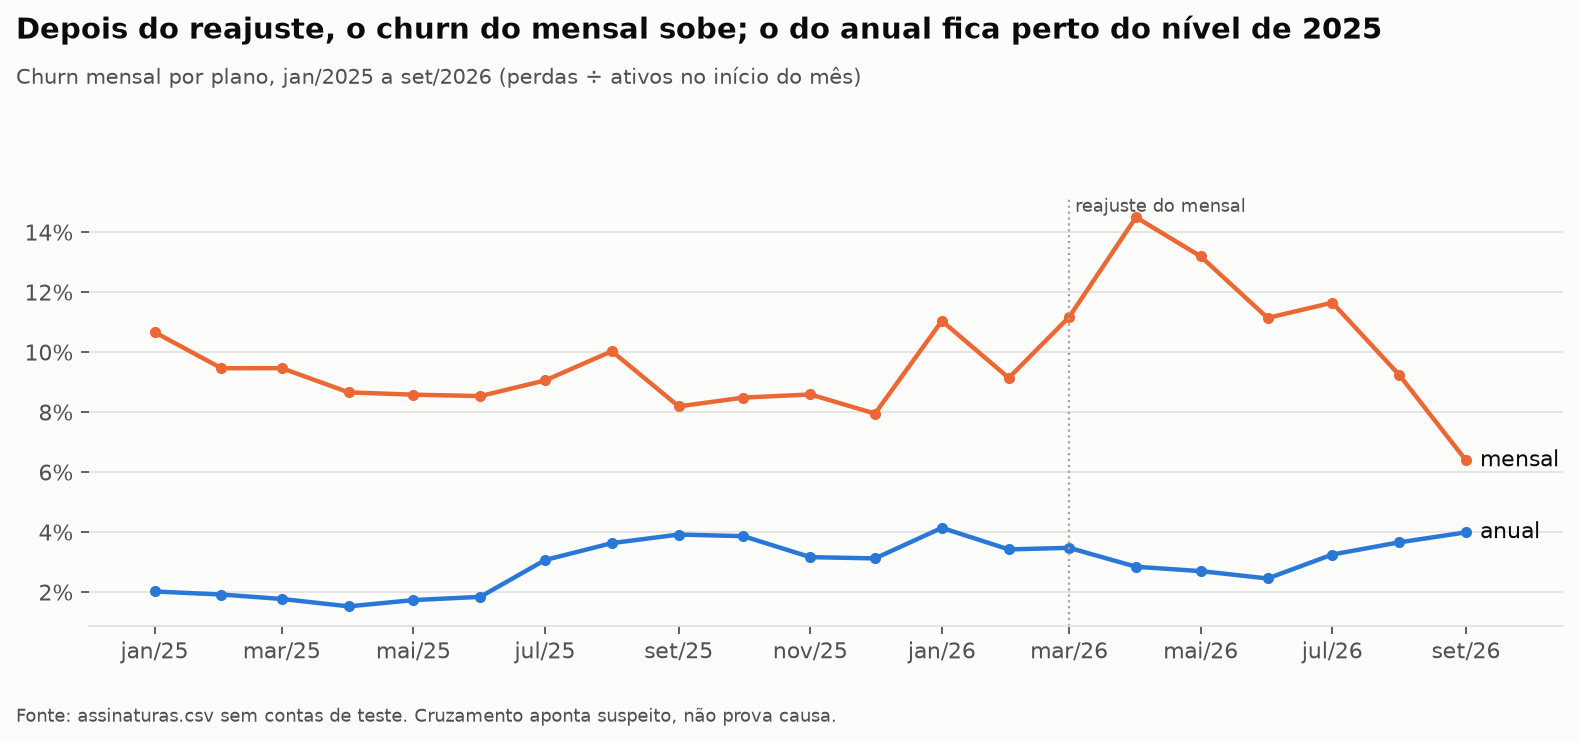

gravado em saidas/eda/03_churn_mensal_por_plano.png


In [7]:
a = pd.read_csv(BRUTOS / "assinaturas.csv", dtype=str, keep_default_na=False)
n0 = len(a)
a = mostrar("assinaturas sem cortesia/teste", a[~(a["plano_atual"].eq("cortesia") | a["user_id"].isin(teste))], n0)
a["inicio_d"] = pd.to_datetime(a["inicio"], format="%Y-%m-%d")
a["fim_d"] = pd.to_datetime(a["data_fim"].replace("", np.nan), format="%Y-%m-%d")
linhas = []
for m in pd.period_range("2025-01", "2026-09", freq="M"):
    s, e = m.start_time, m.end_time.normalize() + pd.Timedelta(days=1)
    ativo = (a["inicio_d"] < s) & (a["fim_d"].isna() | (a["fim_d"] >= s))
    perda = ativo & (a["fim_d"] < e)
    for plano in ["mensal", "anual"]:
        p = a["plano_atual"].eq(plano)
        linhas.append([m.to_timestamp(), plano, int((ativo & p).sum()), int((perda & p).sum())])
por_plano = pd.DataFrame(linhas, columns=["mes", "plano", "ativos", "perdas"])
por_plano["taxa"] = por_plano["perdas"] / por_plano["ativos"]
soma = por_plano.groupby("mes")[["ativos", "perdas"]].sum()
assert (soma["perdas"].values == churn["perdas"].values).all(), "a soma por plano não bate com a série oficial"
print("soma mensal + anual = série oficial: OK")
tab = por_plano.pivot(index="mes", columns="plano", values="taxa")
antes = tab.loc["2025-03":"2026-02"].mean()
depois = tab.loc["2026-03":"2026-05"].mean()
print("média mar/25–fev/26:", (100 * antes).round(1).to_dict(), "· média mar–mai/26:", (100 * depois).round(1).to_dict())

fig, ax = plt.subplots(figsize=(10, 4.6))
for plano, cor in [("mensal", eg.LARANJA), ("anual", eg.AZUL)]:
    s = tab[plano]
    ax.plot(s.index, s.values, color=cor, marker="o", markersize=4)
    ax.text(s.index[-1], s.values[-1], f"  {plano}", color=eg.TEXTO, va="center", fontsize=10)
ax.axvline(pd.Timestamp("2026-03-01"), color=eg.NEUTRO, linewidth=1, linestyle=":")
ax.text(pd.Timestamp("2026-03-01"), ax.get_ylim()[1], " reajuste do mensal", color=eg.TEXTO_2, fontsize=8, va="top")
ax.yaxis.set_major_formatter(eg.pct())
ax.grid(axis="x", visible=False)
ax.set_xlim(right=tab.index[-1] + pd.Timedelta(days=45))
eg.eixo_meses(ax)
eg.titulo(fig, "Depois do reajuste, o churn do mensal sobe; o do anual fica perto do nível de 2025",
          "Churn mensal por plano, jan/2025 a set/2026 (perdas ÷ ativos no início do mês)")
eg.fonte(fig, "Fonte: assinaturas.csv sem contas de teste. Cruzamento aponta suspeito, não prova causa.")
eg.ajustar(fig)
mostrar_grafico(fig, "03_churn_mensal_por_plano.png")

## 3. Padrões e correlações com a saída

### 3.1 A base: uma linha por assinante, sem vazamento
Para comparar quem sai com quem fica, cada assinante ativo num corte vira uma linha, com tudo medido **até o corte** (treinos, uso do app, pagamentos, suporte, social) e o rótulo `saiu_60d` = a assinatura terminou nos 60 dias seguintes. A base é de `src/base_assinantes.py` (decisões 33 a 36).

O corte principal aqui é **30/06/2026**. Os cortes de 30/04 e 31/05 servem para ver se o padrão se repete.

In [8]:
cortes = ["2026-04-30", "2026-05-31", "2026-06-30"]
bases = {c: pd.read_parquet(PROCESSADOS / f"base_assinantes_{c}.parquet") for c in cortes}
for c, b in bases.items():
    assert b["user_id"].is_unique and not b["user_id"].isin(teste).any()
    print(f"[linhas] corte {c}: {len(b):,} assinantes · saíram em 60 dias {b['saiu_60d'].sum():,} ({b['saiu_60d'].mean():.2%})".replace(",", "."))
b6 = bases["2026-06-30"].copy()
TAXA_GERAL = b6["saiu_60d"].mean()

[linhas] corte 2026-04-30: 14.119 assinantes · saíram em 60 dias 1.783 (12.63%)
[linhas] corte 2026-05-31: 14.102 assinantes · saíram em 60 dias 1.703 (12.08%)
[linhas] corte 2026-06-30: 14.059 assinantes · saíram em 60 dias 1.675 (11.91%)


### 3.2 Taxa de saída por característica
Cada barra é a % de quem saiu em 60 dias dentro do grupo. A linha cinza é a taxa geral do corte.

In [9]:
def faixa_tempo(d):
    return pd.cut(d, [-1, 90, 180, 365, 730, 10_000], labels=["até 3 meses", "3–6 meses", "6–12 meses", "1–2 anos", "mais de 2 anos"])

b6["tempo_de_casa"] = faixa_tempo(b6["tenure_dias"])
b6["renovacao"] = np.where(b6["renovacao_desligada"], "desligada", "ligada")
b6["recusa_90d"] = np.where(b6["pg_recusas_90d"] > 0, "teve recusa", "sem recusa")
b6["ticket_90d"] = np.where(b6["n_tickets_90d"] > 0, "abriu chamado", "sem chamado")
b6["treinou_30d"] = np.where(b6["treinos_30d"] > 0, "treinou", "não treinou")
b6["questionario"] = np.where(b6["sem_questionario"], "não respondeu", "respondeu")
FATORES = {
    "Renovação automática": "renovacao", "Plano": "plano_atual", "Treinou nos últimos 30 dias": "treinou_30d",
    "Tempo de casa": "tempo_de_casa", "Canal de cobrança": "canal_cobranca", "Recusa de pagamento (90 dias)": "recusa_90d",
    "Chamado no suporte (90 dias)": "ticket_90d", "Canal de aquisição": "canal_aquisicao",
}
print("assinantes de 30/06 sem questionário de entrada:", int(b6["sem_questionario"].sum()), "(o fator não separa ninguém e fica fora)")
resumo = []
for nome, col in FATORES.items():
    g = b6.groupby(col, observed=True)["saiu_60d"].agg(["mean", "size", "sum"])
    for cat, r in g.iterrows():
        resumo.append([nome, str(cat), r["size"], int(r["sum"]), r["mean"]])
resumo = pd.DataFrame(resumo, columns=["fator", "grupo", "assinantes", "saíram", "taxa"])
amplitude = resumo.groupby("fator")["taxa"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False).rename("amplitude (p.p.)")
print((100 * amplitude).round(1).to_string())
resumo.assign(taxa=(100 * resumo["taxa"]).round(1))

assinantes de 30/06 sem questionário de entrada: 0 (o fator não separa ninguém e fica fora)
fator
Renovação automática             23.5
Plano                            12.7
Tempo de casa                     9.8
Recusa de pagamento (90 dias)     8.6
Treinou nos últimos 30 dias       5.7
Chamado no suporte (90 dias)      4.0
Canal de aquisição                4.0
Canal de cobrança                 3.3


,fator,grupo,assinantes,saíram,taxa
0,Renovação automática,desligada,2336.0,737,31.5
1,Renovação automática,ligada,11723.0,938,8.0
2,Plano,anual,8212.0,546,6.6
3,Plano,mensal,5847.0,1129,19.3
4,Treinou nos últimos 30 dias,não treinou,1802.0,305,16.9
5,Treinou nos últimos 30 dias,treinou,12257.0,1370,11.2
6,Tempo de casa,até 3 meses,2619.0,391,14.9
7,Tempo de casa,3–6 meses,2798.0,318,11.4
8,Tempo de casa,6–12 meses,3497.0,562,16.1
9,Tempo de casa,1–2 anos,3540.0,303,8.6


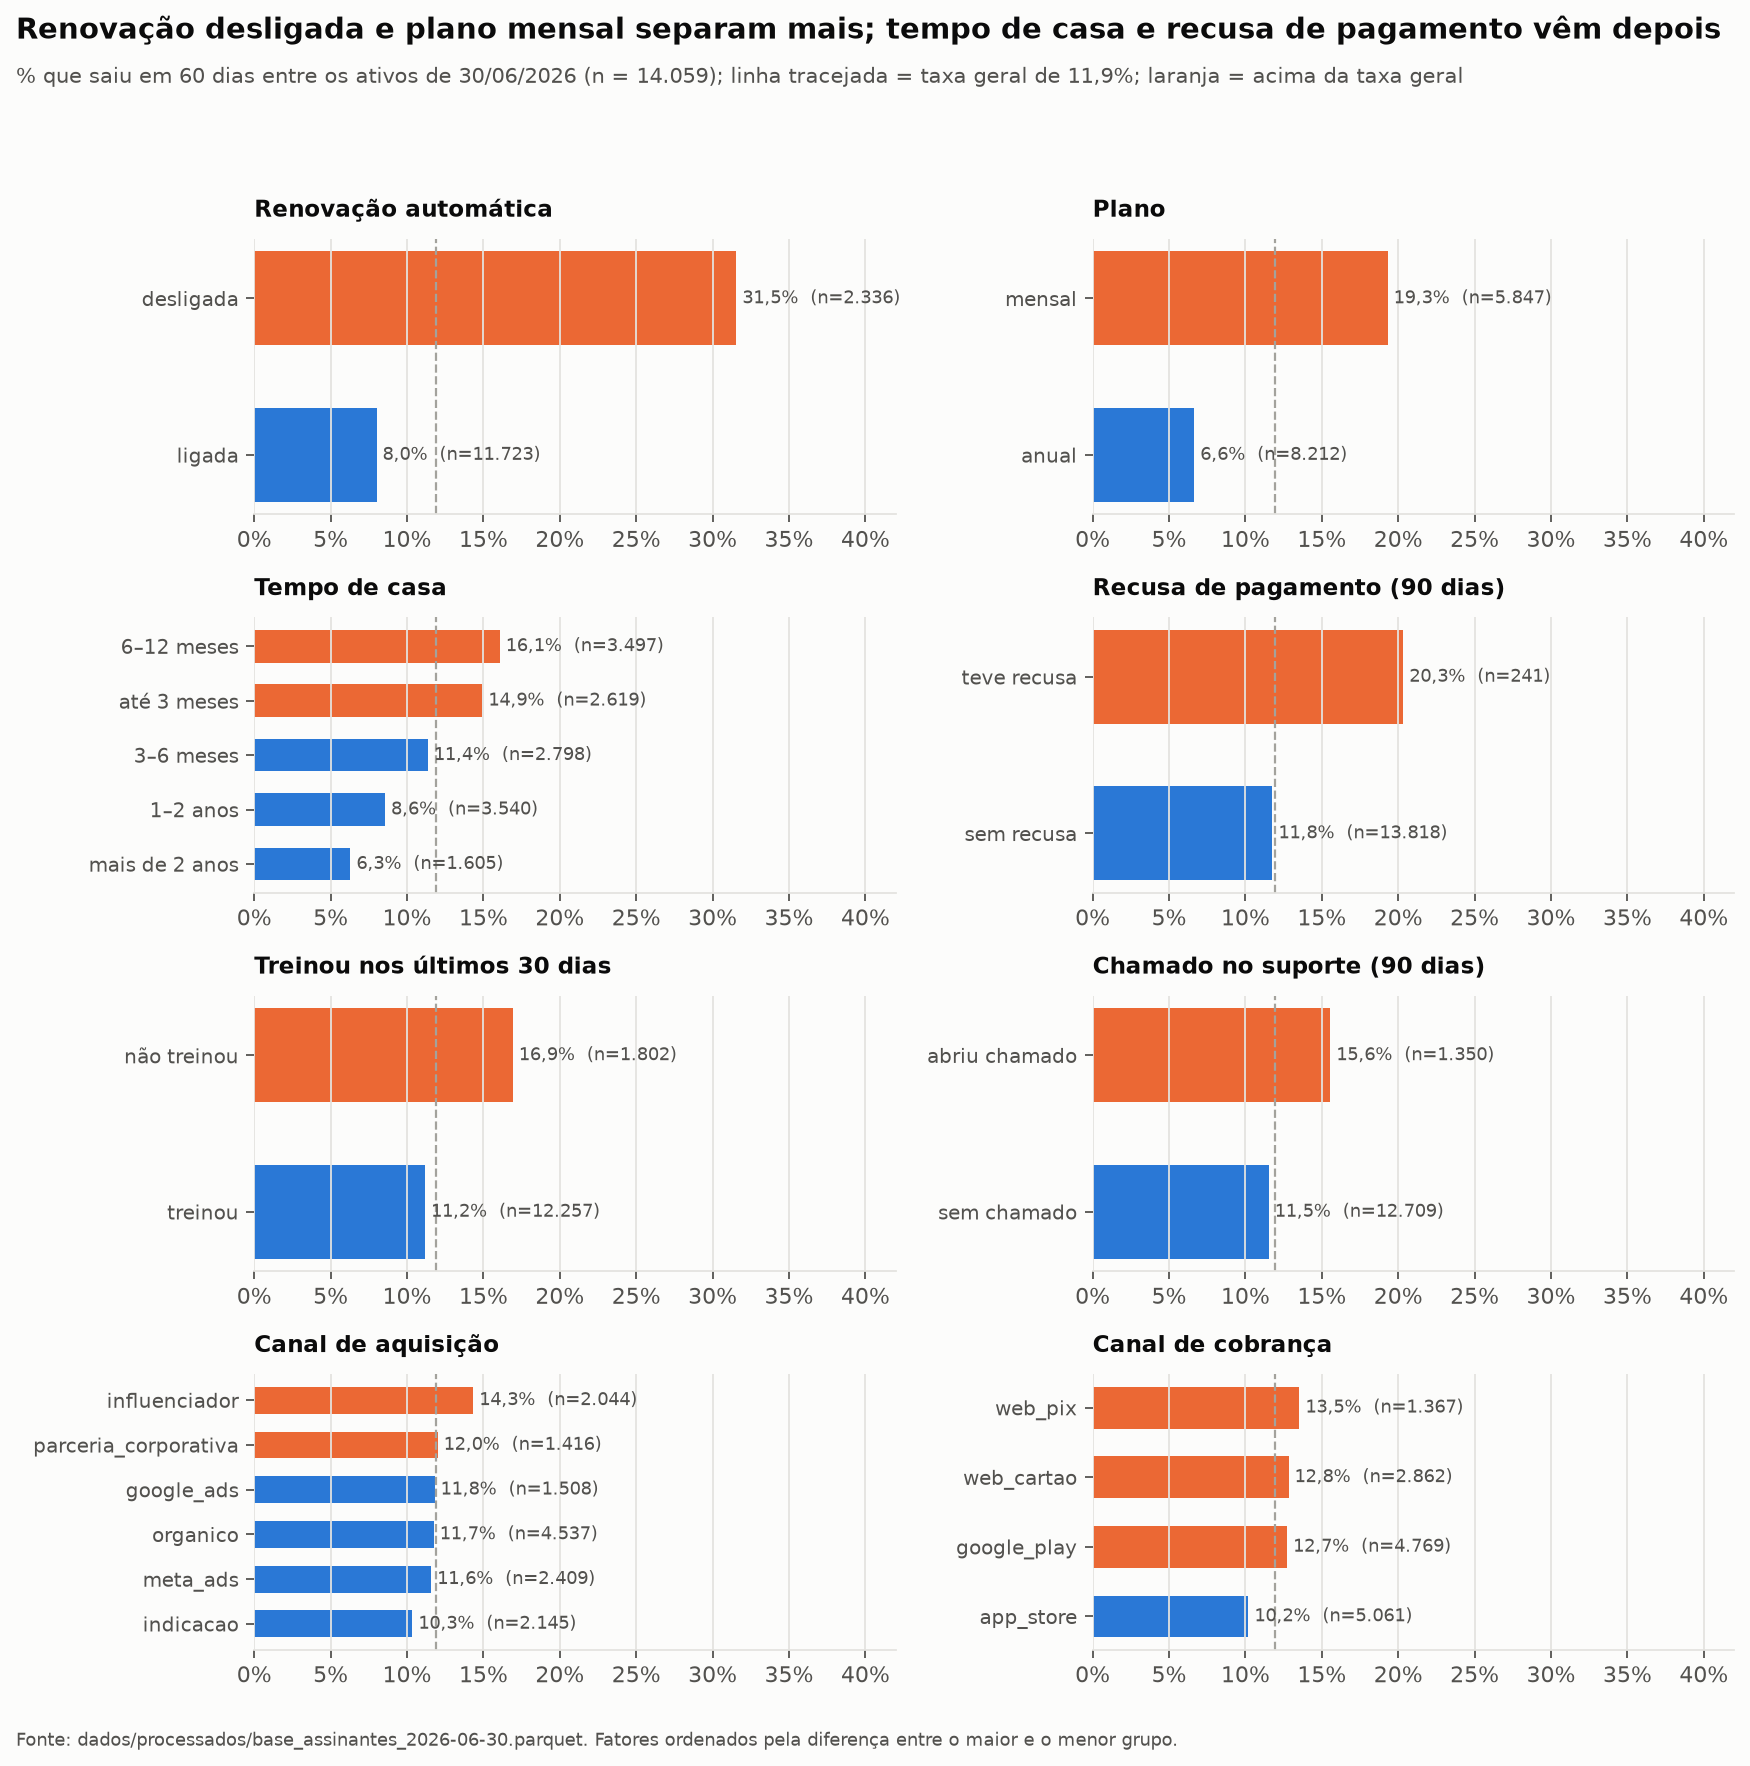

gravado em saidas/eda/04_saida_por_caracteristica.png


In [10]:
ordem = amplitude.index[:8]
fig, axes = plt.subplots(4, 2, figsize=(11, 11))
for ax, fator in zip(axes.flat, ordem):
    d = resumo[resumo["fator"] == fator].sort_values("taxa")
    ax.barh(d["grupo"], d["taxa"], color=[eg.LARANJA if t > TAXA_GERAL else eg.AZUL for t in d["taxa"]], height=0.6)
    ax.axvline(TAXA_GERAL, color=eg.NEUTRO, linewidth=1, linestyle="--")
    for y, (t, n) in enumerate(zip(d["taxa"], d["assinantes"])):
        ax.text(t, y, f" {eg.br(100 * t)}%  (n={eg.br(n, 0)})", va="center", fontsize=8, color=eg.TEXTO_2)
    ax.set_title(fator, fontsize=10.5)
    ax.xaxis.set_major_formatter(eg.pct())
    ax.set_xlim(0, max(0.42, resumo["taxa"].max() * 1.25))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
eg.titulo(fig, "Renovação desligada e plano mensal separam mais; tempo de casa e recusa de pagamento vêm depois",
          f"% que saiu em 60 dias entre os ativos de 30/06/2026 (n = {eg.br(len(b6), 0)}); linha tracejada = taxa geral de {eg.br(100 * TAXA_GERAL)}%; laranja = acima da taxa geral")
eg.fonte(fig, "Fonte: dados/processados/base_assinantes_2026-06-30.parquet. Fatores ordenados pela diferença entre o maior e o menor grupo.")
eg.ajustar(fig)
mostrar_grafico(fig, "04_saida_por_caracteristica.png")

**Leitura.** Quem desligou a renovação sai 31,5% das vezes, contra 8,0% com ela ligada; o mensal sai 19,3%, contra 6,6% do anual. O tempo de casa não é uma linha reta: o pico em **6–12 meses** coincide com o fim do primeiro ano, quando o anual renova (e o desconto de influenciador do 1º ano acaba). Canal de cobrança e canal de aquisição separam pouco.

### 3.3 O padrão se repete nos três cortes?
Uma diferença que só aparece num corte pode ser acaso. Aqui os principais grupos de risco são medidos em 30/04, 31/05 e 30/06.

,corte 2026-04-30,corte 2026-05-31,corte 2026-06-30
renovação desligada,35.7,31.8,31.5
renovação ligada,8.7,8.5,8.0
plano mensal,22.3,20.8,19.3
plano anual,5.2,5.6,6.6
sem treino em 30 dias,15.7,16.9,16.9
treinou em 30 dias,12.2,11.5,11.2
recusa de pagamento em 90 dias,19.1,22.7,20.3


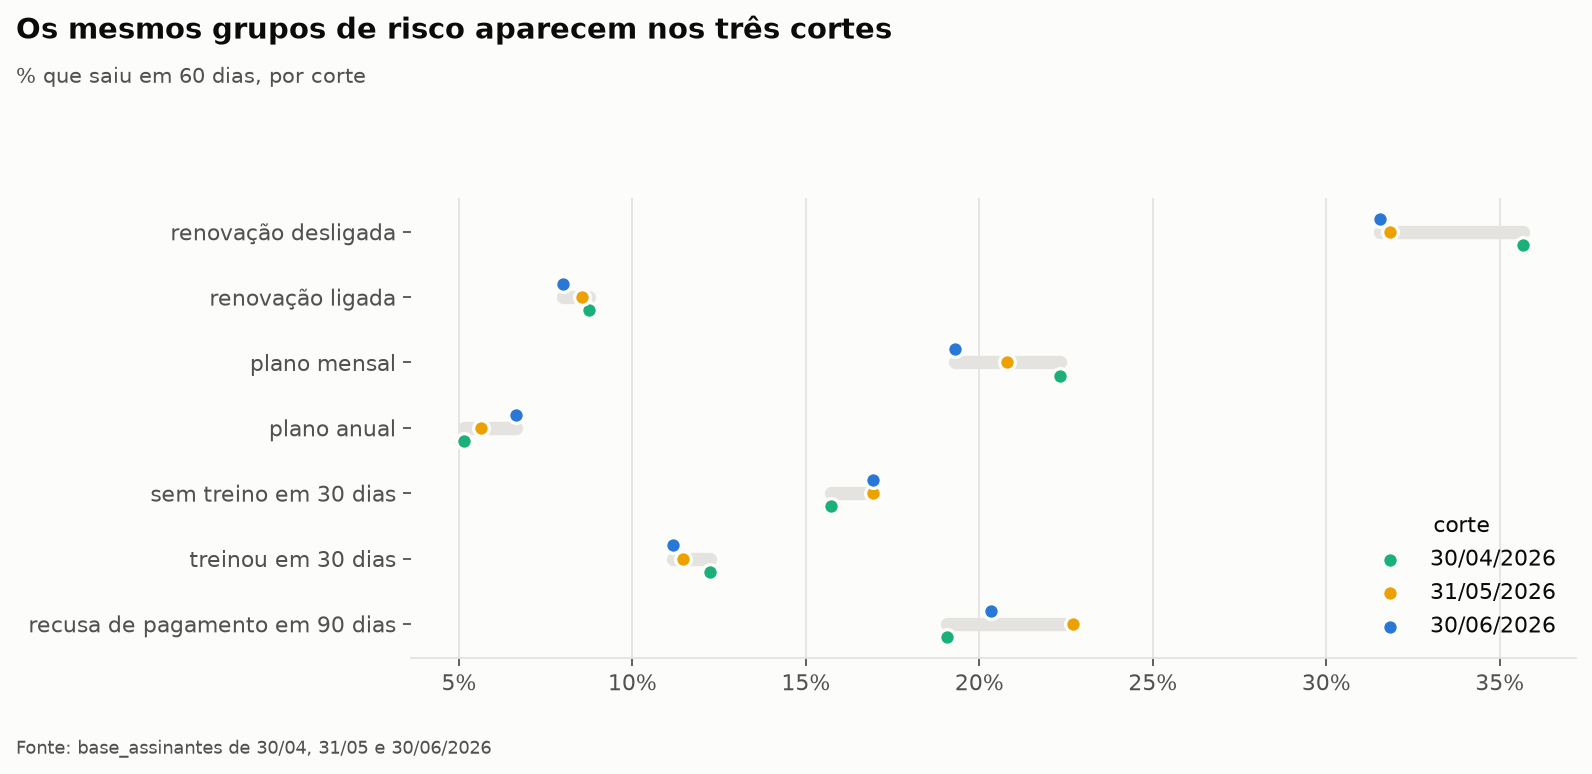

gravado em saidas/eda/05_consistencia_entre_cortes.png


In [11]:
regras = {
    "renovação desligada": lambda b: b["renovacao_desligada"],
    "renovação ligada": lambda b: ~b["renovacao_desligada"],
    "plano mensal": lambda b: b["plano_atual"].eq("mensal"),
    "plano anual": lambda b: b["plano_atual"].eq("anual"),
    "sem treino em 30 dias": lambda b: b["treinos_30d"].eq(0),
    "treinou em 30 dias": lambda b: b["treinos_30d"].gt(0),
    "recusa de pagamento em 90 dias": lambda b: b["pg_recusas_90d"].gt(0),
}
cons = pd.DataFrame({c: {r: bases[c].loc[f(bases[c]), "saiu_60d"].mean() for r, f in regras.items()} for c in cortes})
display((100 * cons).round(1).rename(columns=lambda c: f"corte {c}"))

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(cons))[::-1]
for c, cor, desloc in zip(cortes, [eg.AQUA, eg.AMARELO, eg.AZUL], [-0.2, 0, 0.2]):
    ax.scatter(cons[c], y + desloc, color=cor, s=50, zorder=3, label=pd.Timestamp(c).strftime("%d/%m/%Y"), edgecolor=eg.FUNDO, linewidth=1.5)
for yi, (_, r) in zip(y, cons.iterrows()):
    ax.plot([r.min(), r.max()], [yi, yi], color=eg.GRADE, linewidth=6, zorder=1, solid_capstyle="round")
ax.set_yticks(y, cons.index)
ax.xaxis.set_major_formatter(eg.pct())
ax.grid(axis="y", visible=False)
ax.legend(title="corte", loc="lower right")
eg.titulo(fig, "Os mesmos grupos de risco aparecem nos três cortes", "% que saiu em 60 dias, por corte")
eg.fonte(fig, "Fonte: base_assinantes de 30/04, 31/05 e 30/06/2026")
eg.ajustar(fig)
mostrar_grafico(fig, "05_consistencia_entre_cortes.png")

### 3.4 Uso do app e treinos: quem sai × quem fica

saiu_60d,ficou (mediana),saiu (mediana),diferença
treinos_90d,24.0,18.0,-6.0
recencia_dias,3.0,6.0,3.0
sessoes_app_3m,6.3,4.3,-2.0
minutos_90d,1060.9,817.2,-243.7


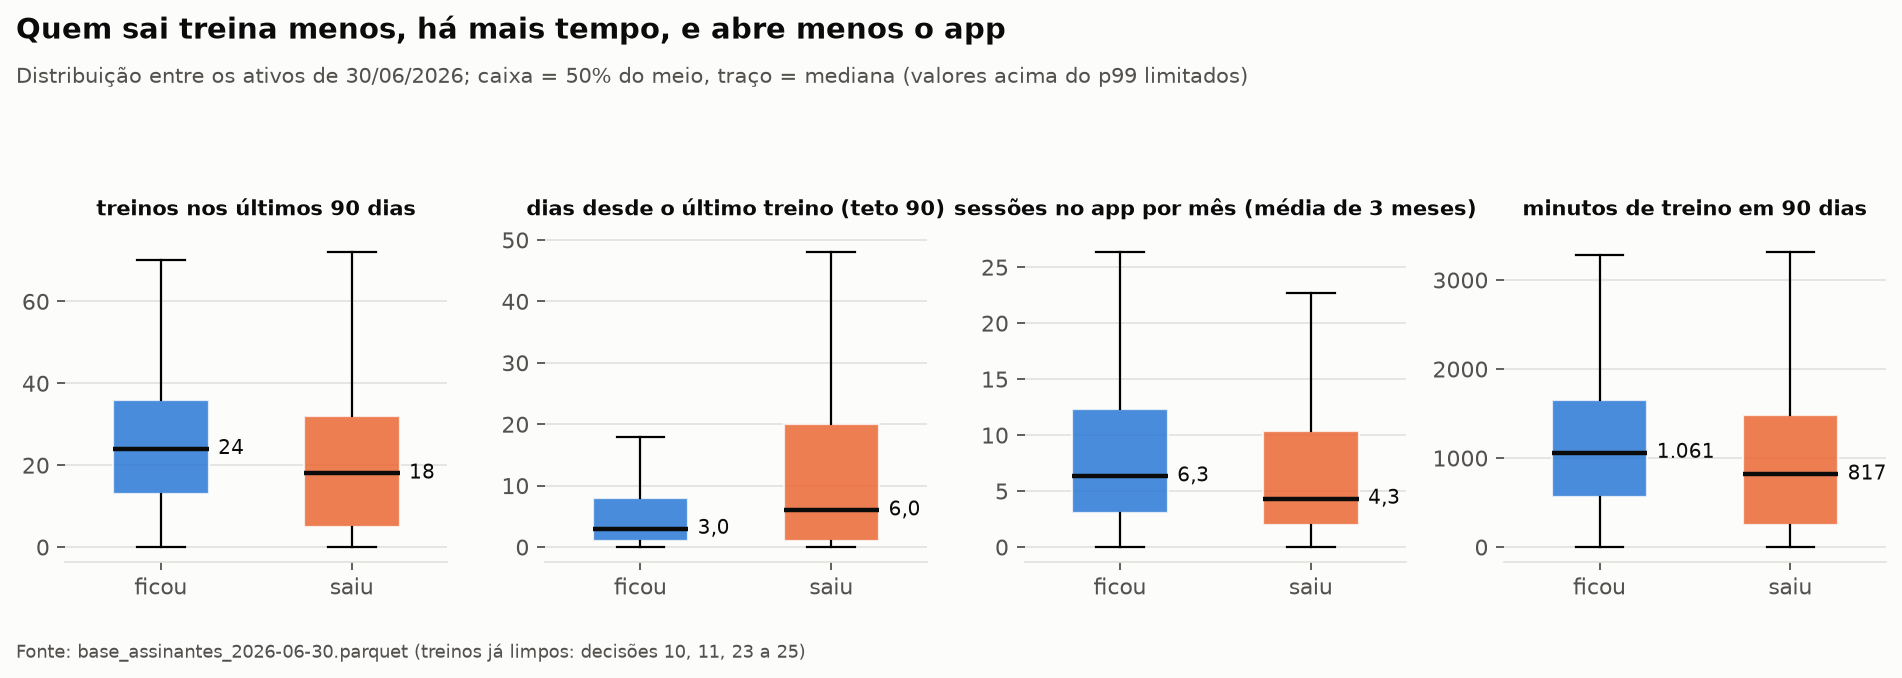

gravado em saidas/eda/06_uso_saiu_x_ficou.png


In [12]:
USO = {"treinos_90d": "treinos nos últimos 90 dias", "recencia_dias": "dias desde o último treino (teto 90)",
       "sessoes_app_3m": "sessões no app por mês (média de 3 meses)", "minutos_90d": "minutos de treino em 90 dias"}
med = b6.groupby("saiu_60d")[list(USO)].median().T.rename(columns={False: "ficou (mediana)", True: "saiu (mediana)"})
med["diferença"] = med["saiu (mediana)"] - med["ficou (mediana)"]
display(med.round(1))

fig, axes = plt.subplots(1, 4, figsize=(12, 4.2))
for ax, (col, rotulo) in zip(axes, USO.items()):
    dados = [b6.loc[~b6["saiu_60d"], col].clip(upper=b6[col].quantile(0.99)), b6.loc[b6["saiu_60d"], col].clip(upper=b6[col].quantile(0.99))]
    bp = ax.boxplot(dados, tick_labels=["ficou", "saiu"], widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color=eg.TEXTO, linewidth=2))
    for caixa, cor in zip(bp["boxes"], [eg.FICOU, eg.SAIU]):
        caixa.set(facecolor=cor, alpha=0.85, edgecolor=eg.FUNDO)
    for i, d in enumerate(dados, start=1):
        ax.text(i + 0.3, d.median(), eg.br(d.median(), 0 if d.median() >= 10 else 1), va="center", fontsize=9, color=eg.TEXTO)
    ax.set_title(rotulo, fontsize=9.5, loc="center", wrap=True)
    ax.grid(axis="x", visible=False)
eg.titulo(fig, "Quem sai treina menos, há mais tempo, e abre menos o app",
          "Distribuição entre os ativos de 30/06/2026; caixa = 50% do meio, traço = mediana (valores acima do p99 limitados)")
eg.fonte(fig, "Fonte: base_assinantes_2026-06-30.parquet (treinos já limpos: decisões 10, 11, 23 a 25)")
eg.ajustar(fig)
mostrar_grafico(fig, "06_uso_saiu_x_ficou.png")

### 3.5 Correlação de cada variável com a saída
Correlação de Spearman entre cada variável numérica e `saiu_60d` (0 = ficou, 1 = saiu). Valor positivo: quanto maior a variável, maior a saída. Duas famílias são separadas:
- **sinais de saída** (renovação desligada, dias até o fim do período): quase são o próprio desfecho, pois a pessoa já avisou que vai sair. Servem para agir rápido, não para explicar o porquê.
- **reflexos do plano** (número de renovações, valor médio pago, cobranças aprovadas): o mensal renova e cobra todo mês, com valor menor; essas variáveis repetem o efeito do plano.
- **comportamento e perfil**: o que pode antecipar a saída antes do aviso.

,spearman,família
dias_ate_fim_periodo,-0.297,sinal de saída
renovacao_desligada,0.271,sinal de saída
dias_desde_desligamento,0.251,sinal de saída
n_renovacoes,0.188,reflexo do plano
pg_valor_medio,-0.146,reflexo do plano
tem_cancelamento_web,0.135,sinal de saída
recencia_dias,0.119,comportamento/perfil
treinos_30d,-0.106,comportamento/perfil
treinos_total,-0.102,comportamento/perfil
dias_ativos_mes,-0.101,comportamento/perfil


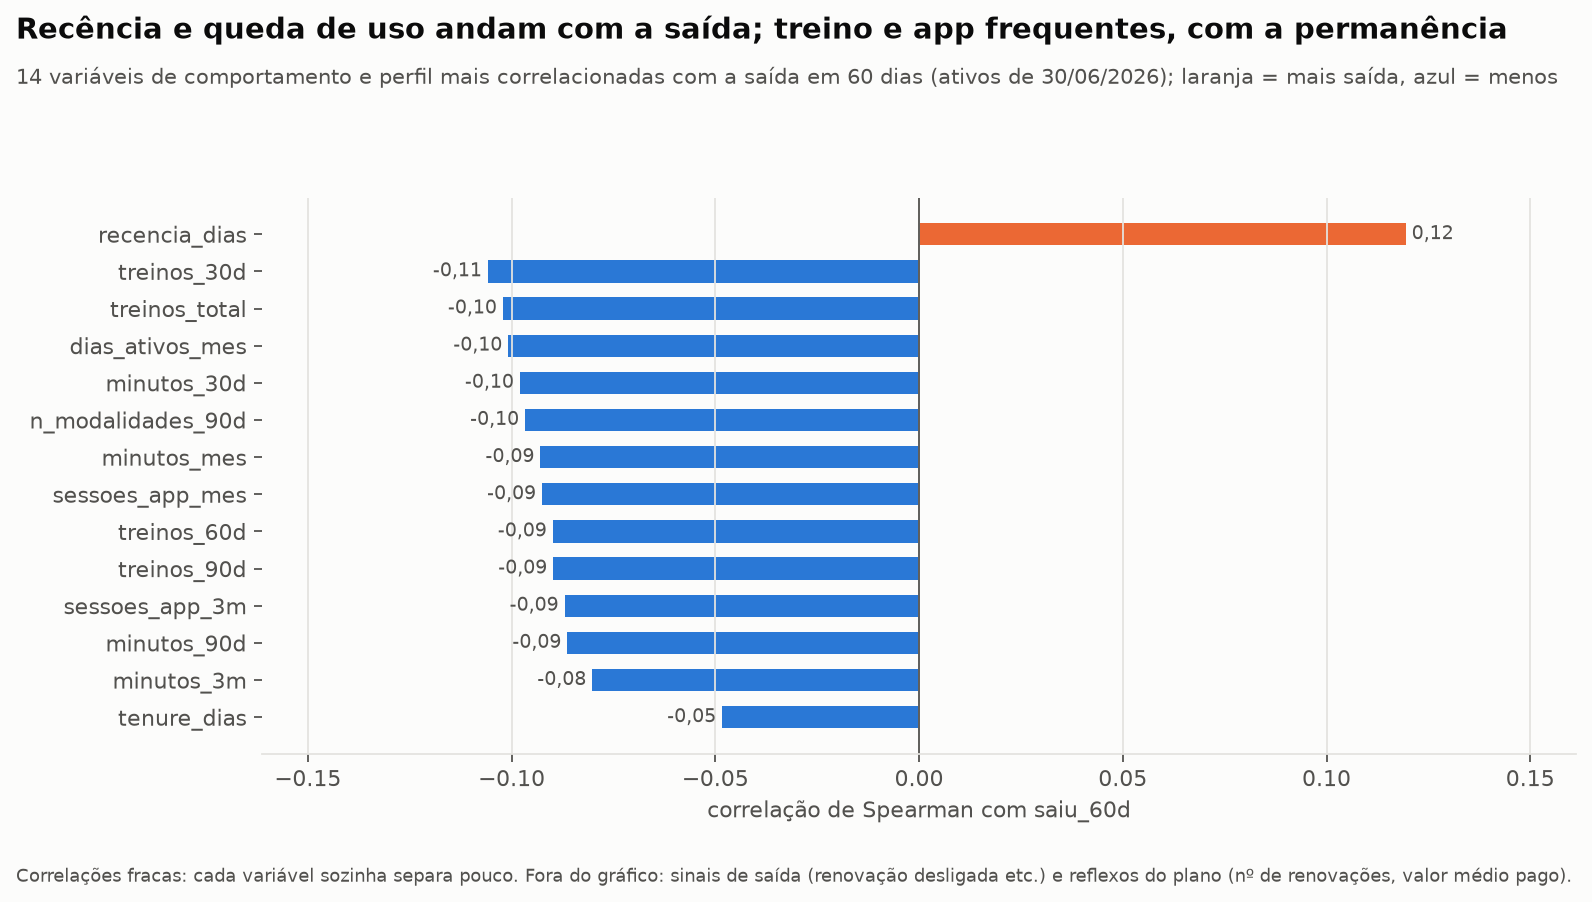

gravado em saidas/eda/07_correlacao_com_saida.png
maiores sinais de saída: {'dias_ate_fim_periodo': -0.297, 'renovacao_desligada': 0.271, 'dias_desde_desligamento': 0.251, 'tem_cancelamento_web': 0.135}


In [13]:
SINAIS = ["renovacao_desligada", "dias_desde_desligamento", "dias_ate_fim_periodo", "tem_cancelamento_web", "n_carencia"]
PLANO = ["n_renovacoes", "pg_valor_medio", "pg_aprovados"]  # refletem o plano: o mensal renova e cobra todo mês, com valor menor
num = b6.select_dtypes(include=["number", "bool"]).drop(columns=["saiu_60d"], errors="ignore")
num = num.loc[:, num.nunique() > 1]
corr = num.astype(float).corrwith(b6["saiu_60d"].astype(float), method="spearman").dropna()
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
tabela_corr = pd.DataFrame({"spearman": corr.round(3), "família": ["sinal de saída" if c in SINAIS else "reflexo do plano" if c in PLANO else "comportamento/perfil" for c in corr.index]})
display(tabela_corr.head(20))

comp = corr[[c for c in corr.index if c not in SINAIS + PLANO]].head(14)[::-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(comp.index, comp.values, color=[eg.LARANJA if v > 0 else eg.AZUL for v in comp.values], height=0.6)
for y, v in enumerate(comp.values):
    ax.text(v, y, f" {eg.br(v, 2)} " if v > 0 else f" {eg.br(v, 2)} ", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=eg.TEXTO_2)
ax.axvline(0, color=eg.TEXTO_2, linewidth=0.8)
ax.grid(axis="y", visible=False)
lim = comp.abs().max() * 1.35
ax.set_xlim(-lim, lim)
ax.set_xlabel("correlação de Spearman com saiu_60d")
eg.titulo(fig, "Recência e queda de uso andam com a saída; treino e app frequentes, com a permanência",
          "14 variáveis de comportamento e perfil mais correlacionadas com a saída em 60 dias (ativos de 30/06/2026); laranja = mais saída, azul = menos")
eg.fonte(fig, "Correlações fracas: cada variável sozinha separa pouco. Fora do gráfico: sinais de saída (renovação desligada etc.) e reflexos do plano (nº de renovações, valor médio pago).")
eg.ajustar(fig)
mostrar_grafico(fig, "07_correlacao_com_saida.png")
print("maiores sinais de saída:", corr[[c for c in corr.index if c in SINAIS]].round(3).to_dict())

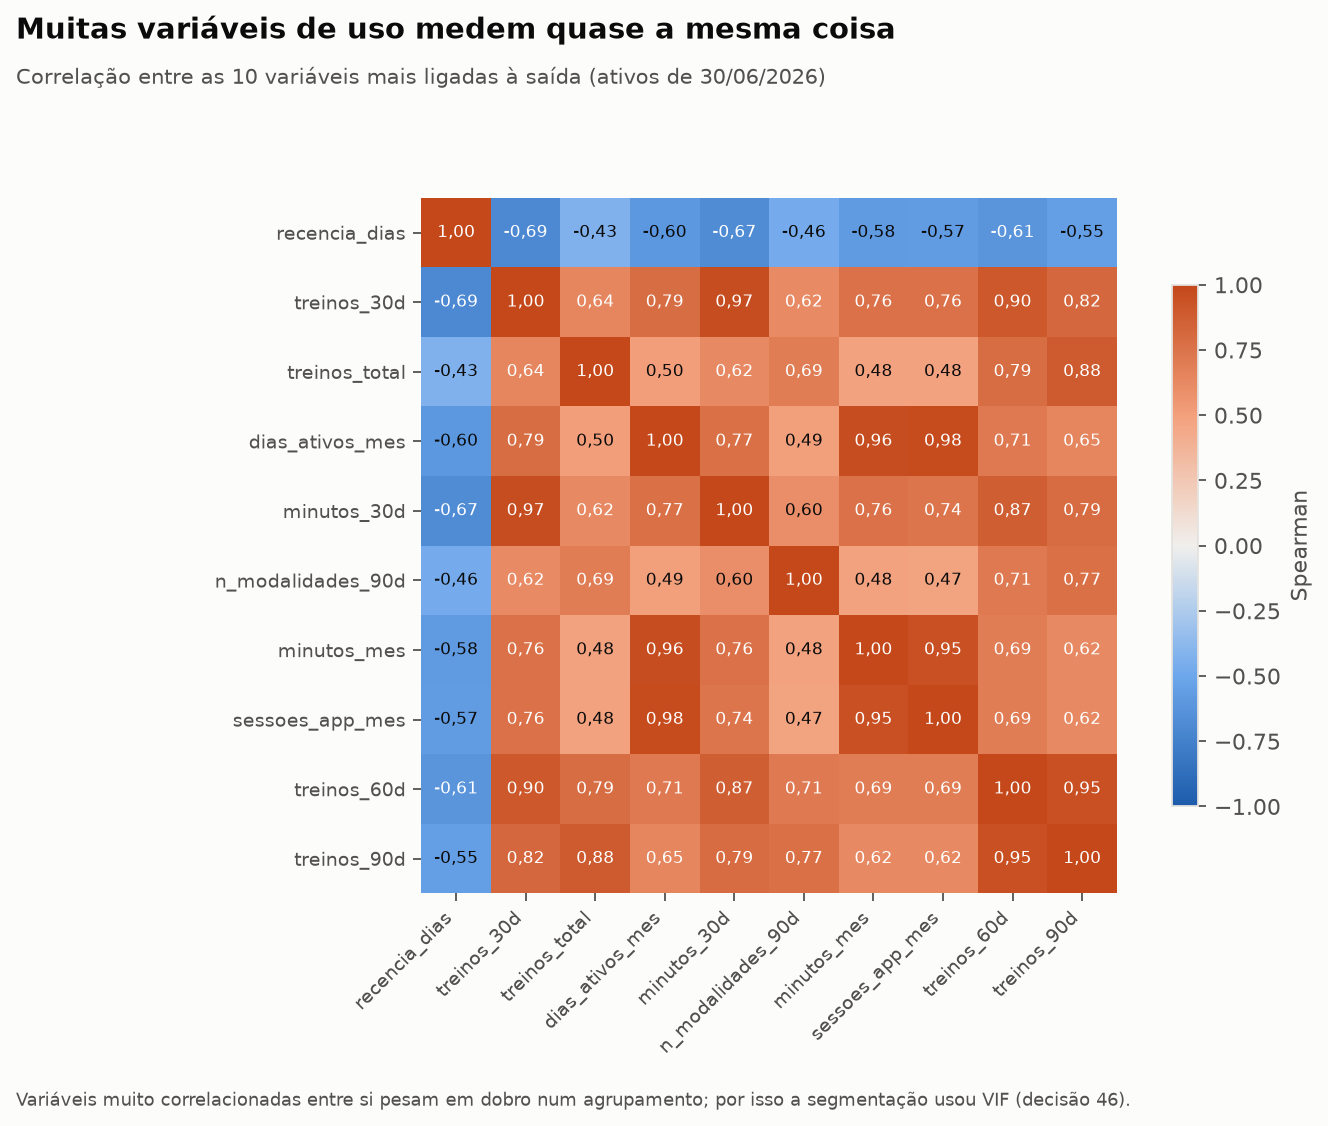

gravado em saidas/eda/08_correlacao_entre_variaveis.png


In [14]:
top = list(comp.index[::-1][:10])
m = b6[top].astype(float).corr(method="spearman")
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", eg.DIVERGENTE)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(m.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(top)), top, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(top)), top, fontsize=8.5)
for i in range(len(top)):
    for j in range(len(top)):
        ax.text(j, i, eg.br(m.values[i, j], 2), ha="center", va="center", fontsize=7.5, color=eg.TEXTO if abs(m.values[i, j]) < 0.6 else "white")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman")
eg.titulo(fig, "Muitas variáveis de uso medem quase a mesma coisa", "Correlação entre as 10 variáveis mais ligadas à saída (ativos de 30/06/2026)")
eg.fonte(fig, "Variáveis muito correlacionadas entre si pesam em dobro num agrupamento; por isso a segmentação usou VIF (decisão 46).")
eg.ajustar(fig)
mostrar_grafico(fig, "08_correlacao_entre_variaveis.png")

## 4. A base empírica da segmentação

A segmentação do grupo (decisões 45 a 47, `saidas/segmentacao_ampliada.md`) é um **K-means com k = 4** sobre 10 variáveis de comportamento dos 14.753 ativos de 30/09/2026. A saída **não** entra no agrupamento: os grupos nascem só do comportamento.

- **Por que essas variáveis:** perfil (sexo, região, canal de aquisição, sistema, forma de pagamento) muda menos de 1% das contas de grupo; as variáveis de uso redundantes saíram pelo VIF.
- **Por que k = 4:** é o k mais estável (ARI K-fold 0,996, bootstrap 0,985). k = 2 tem a maior silhueta, mas só separa ativo de inativo.

Para saber se os segmentos importam para o churn, o modelo de 30/09 classifica os ativos dos cortes rotulados (`src/eda_segmentos_cortes.py`), e a saída em 60 dias é medida em cada segmento.

In [15]:
seg = pd.read_parquet(PROCESSADOS / "segmentos_por_corte.parquet")
print(f"[linhas] segmentos empilhados: {len(seg):,}".replace(",", "."))
s9 = seg[seg["corte"] == "2026-09-30"]
rot = seg[seg["corte"] != "2026-09-30"].copy()
rot["saiu_60d"] = rot["saiu_60d"].astype(bool)
PERS = s9.drop_duplicates("grupo").set_index("grupo")["persona"].sort_index()
tamanho = s9["grupo"].value_counts().sort_index()
saida = rot.groupby("grupo")["saiu_60d"].agg(["mean", "size"])
saida["ic95"] = 1.96 * np.sqrt(saida["mean"] * (1 - saida["mean"]) / saida["size"])
por_corte = rot.pivot_table(index="grupo", columns="corte", values="saiu_60d", aggfunc="mean")
perfil_seg = pd.DataFrame({
    "persona": PERS, "contas em 30/09": tamanho, "% da base": (100 * tamanho / tamanho.sum()).round(1),
    "saiu em 60 dias (3 cortes)": (100 * saida["mean"]).round(1), "± IC 95%": (100 * saida["ic95"]).round(1),
    "% mensal (30/09)": (100 * s9.assign(m=s9["plano_atual"].eq("mensal")).groupby("grupo")["m"].mean()).round(1),
    "% renovação desligada (30/09)": (100 * s9.groupby("grupo")["renovacao_desligada"].mean()).round(1),
})
display(perfil_seg)
display((100 * por_corte).round(1).rename(index=PERS))

[linhas] segmentos empilhados: 57.033


,persona,contas em 30/09,% da base,saiu em 60 dias (3 cortes),± IC 95%,% mensal (30/09),% renovação desligada (30/09)
grupo,,,,,,,
1,Engajado no app,6779,45.9,10.6,0.4,49.7,4.6
2,Engajado com relógio,4390,29.8,10.9,0.5,50.0,6.5
3,Esfriando,2824,19.1,18.6,0.9,24.9,49.2
4,Parado (anual dormente),760,5.2,13.5,1.4,0.4,34.9


corte,2026-04-30,2026-05-31,2026-06-30
grupo,,,
Engajado no app,11.5,10.5,9.9
Engajado com relógio,11.2,10.9,10.6
Esfriando,18.5,19.0,18.4
Parado (anual dormente),12.2,12.0,16.1


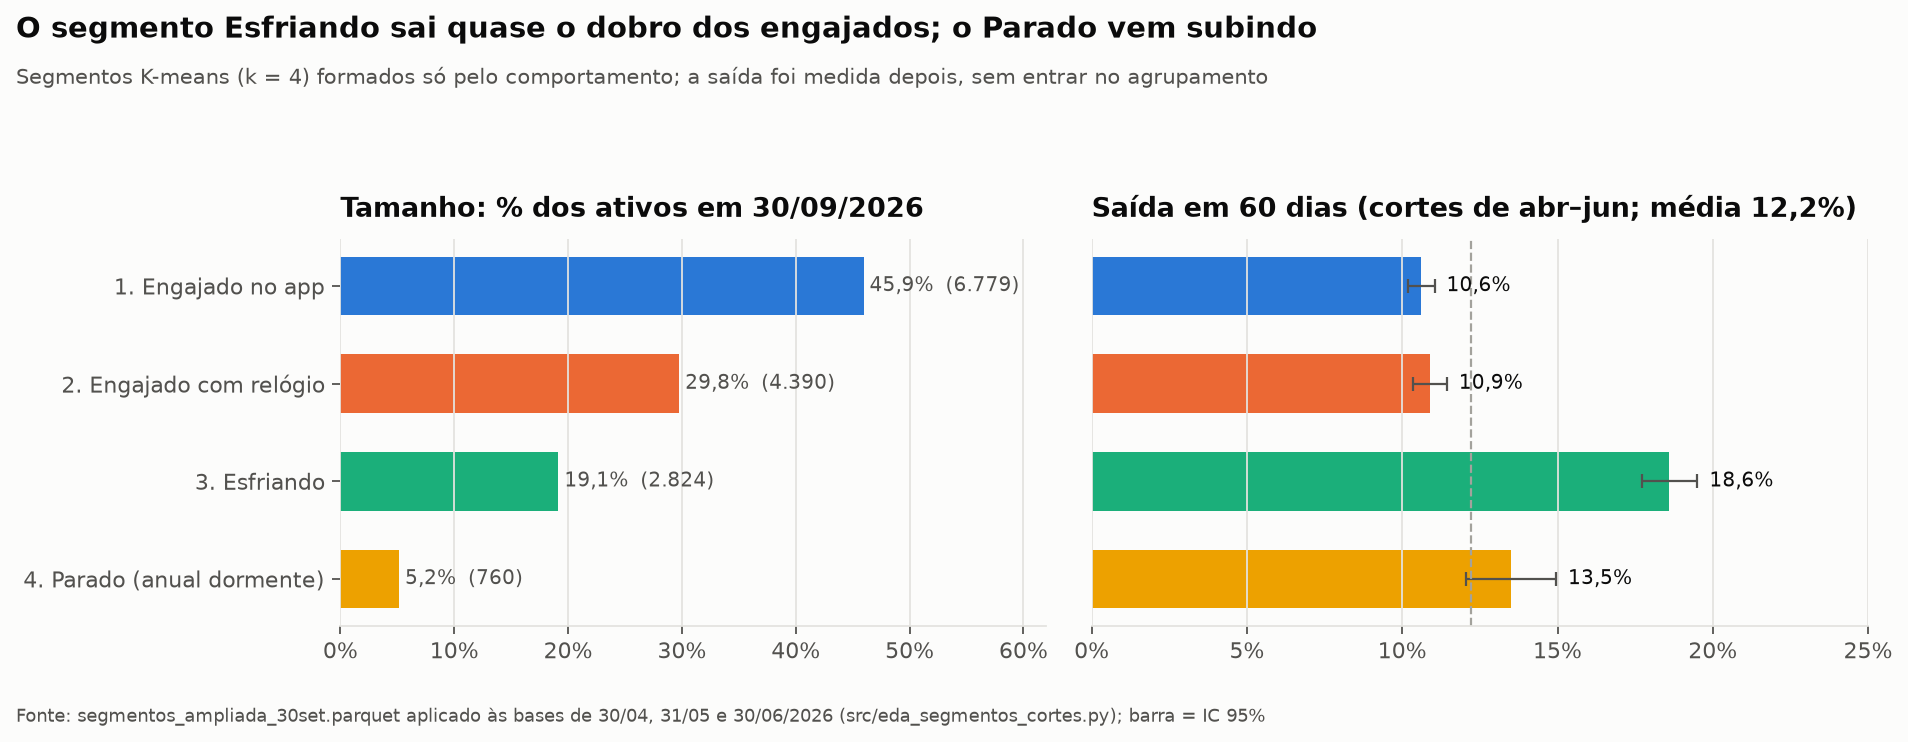

gravado em saidas/eda/09_segmentos_tamanho_e_saida.png


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1, 1.1]))
nomes = [f"{g}. {PERS[g]}" for g in PERS.index][::-1]
cores = [eg.CORES_SEGMENTO[g] for g in PERS.index][::-1]
ax1.barh(nomes, (tamanho / tamanho.sum()).values[::-1], color=cores, height=0.6)
for y, (p, n) in enumerate(zip((tamanho / tamanho.sum()).values[::-1], tamanho.values[::-1])):
    ax1.text(p, y, f" {eg.br(100 * p)}%  ({eg.br(n, 0)})", va="center", fontsize=9, color=eg.TEXTO_2)
ax1.set_xlim(0, 0.62)
ax1.xaxis.set_major_formatter(eg.pct())
ax1.set_title("Tamanho: % dos ativos em 30/09/2026")
ax1.grid(axis="y", visible=False)
taxa = saida["mean"].values[::-1]
erro = saida["ic95"].values[::-1]
ax2.barh(nomes, taxa, xerr=erro, color=cores, height=0.6, error_kw=dict(ecolor=eg.TEXTO_2, capsize=3, linewidth=1))
media_rot = rot["saiu_60d"].mean()
ax2.axvline(media_rot, color=eg.NEUTRO, linestyle="--", linewidth=1)
for y, (t, e) in enumerate(zip(taxa, erro)):
    ax2.text(t + e, y, f"  {eg.br(100 * t)}%", va="center", fontsize=9, color=eg.TEXTO)
ax2.set_yticks([])
ax2.set_xlim(0, 0.25)
ax2.xaxis.set_major_formatter(eg.pct())
ax2.set_title(f"Saída em 60 dias (cortes de abr–jun; média {eg.br(100 * media_rot)}%)")
ax2.grid(axis="y", visible=False)
eg.titulo(fig, "O segmento Esfriando sai quase o dobro dos engajados; o Parado vem subindo", "Segmentos K-means (k = 4) formados só pelo comportamento; a saída foi medida depois, sem entrar no agrupamento")
eg.fonte(fig, "Fonte: segmentos_ampliada_30set.parquet aplicado às bases de 30/04, 31/05 e 30/06/2026 (src/eda_segmentos_cortes.py); barra = IC 95%")
eg.ajustar(fig)
mostrar_grafico(fig, "09_segmentos_tamanho_e_saida.png")

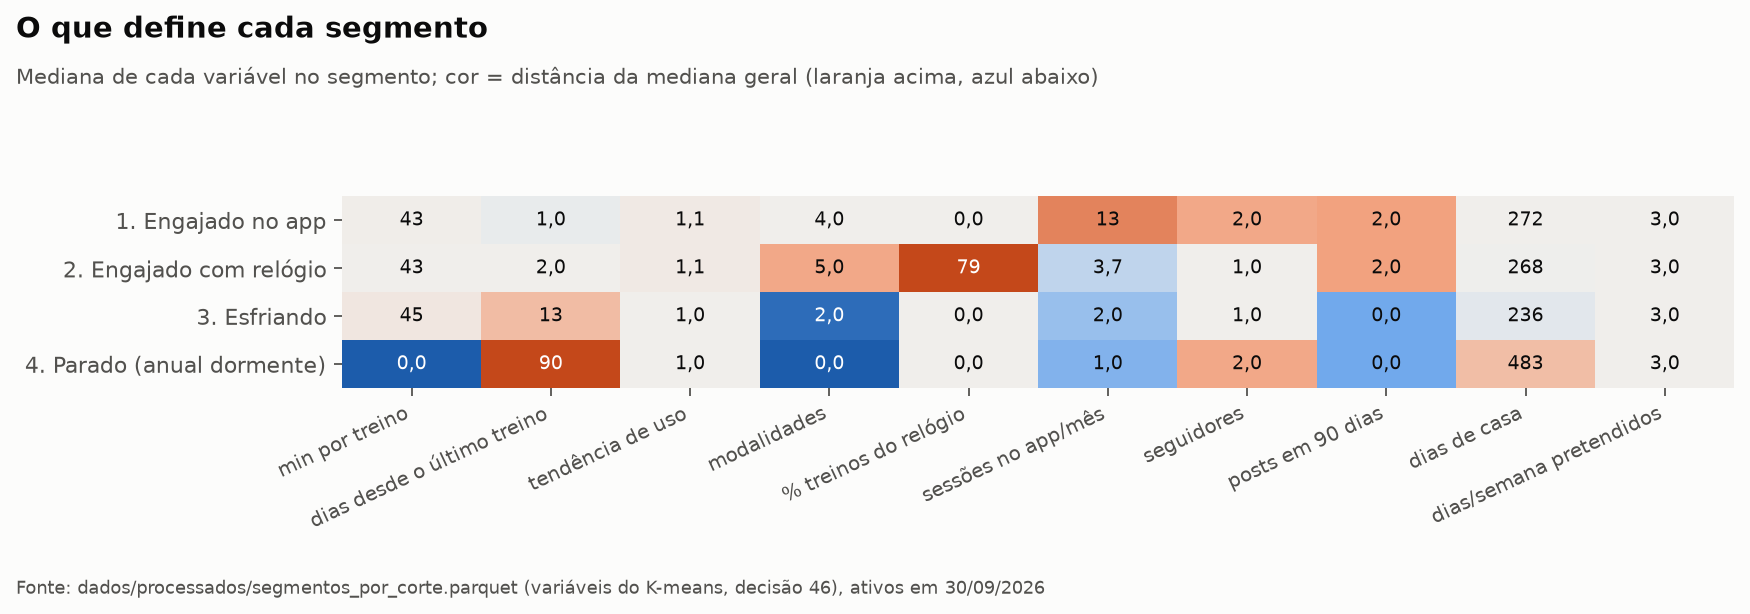

gravado em saidas/eda/10_perfil_dos_segmentos.png


In [17]:
VARS = {"minutos_por_treino_90d": "min por treino", "recencia_dias": "dias desde o último treino", "tendencia": "tendência de uso",
        "n_modalidades_90d": "modalidades", "pct_relogio_90d": "% treinos do relógio", "sessoes_app_3m": "sessões no app/mês",
        "n_seguidores": "seguidores", "n_posts_90d": "posts em 90 dias", "dias_desde_cadastro": "dias de casa", "dias_semana": "dias/semana pretendidos"}
disp = list(VARS)
p9 = s9
medianas = p9.groupby("grupo")[disp].median()
z = (medianas - p9[disp].median()) / p9[disp].std()
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(z.values, cmap=LinearSegmentedColormap.from_list("div", eg.DIVERGENTE), vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(disp)), [VARS[v] for v in disp], rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(4), [f"{g}. {PERS[g]}" for g in medianas.index])
for i in range(4):
    for j, v in enumerate(disp):
        ax.text(j, i, eg.br(medianas.iloc[i, j], 0 if medianas.iloc[i, j] >= 10 else 1), ha="center", va="center", fontsize=8.5,
                color="white" if abs(z.iloc[i, j]) > 1 else eg.TEXTO)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
eg.titulo(fig, "O que define cada segmento", "Mediana de cada variável no segmento; cor = distância da mediana geral (laranja acima, azul abaixo)")
eg.fonte(fig, "Fonte: dados/processados/segmentos_por_corte.parquet (variáveis do K-means, decisão 46), ativos em 30/09/2026")
eg.ajustar(fig)
mostrar_grafico(fig, "10_perfil_dos_segmentos.png")

**Leitura dos segmentos**

| # | Persona | O que define | Hipótese de driver de churn |
|---|---|---|---|
| 1 | Engajado no app | treina com frequência e registra pelo app, sem relógio; é quem mais abre o app | preço no mensal (metade é mensal) |
| 2 | Engajado com relógio | treina tanto quanto o 1, mas a maior parte dos treinos vem do relógio; abre pouco o app | o app vira só um "cofre" de dados do relógio: valor percebido baixo |
| 3 | Esfriando | poucos treinos, último há quase duas semanas, quase nada no app e no social; metade já desligou a renovação | perda de hábito; já avisou que vai sair |
| 4 | Parado (anual dormente) | nenhum treino em 90 dias; quase todos no plano anual | paga e não usa: sai na renovação anual |

As hipóteses são suspeitos para o relatório de Negócios testar. A segmentação descreve; não prova o motivo da saída.

## 5. Limitações da análise

- **Correlação não é causa.** O pico de abril coincide com o reajuste do mensal, mas a campanha, a sazonalidade e a mudança no registro do uso (zeros em 2026) também mudaram no período. Nada aqui foi testado como causa.
- **Motivo da saída é quase invisível.** Quem paga pela loja (cerca de 70%) cancela fora do app: a Vitaliza só recebe `renovacao_automatica_desligada` e `assinatura_expirada`, sem motivo. A pesquisa de saída só aparece para quem paga pelo site (353 respostas de 3.389 fins em jun–set): **viés de seleção**.
- **Sinais de saída quase iguais ao desfecho.** Renovação desligada separa muito, mas é um aviso, não uma causa. Um modelo preditivo deve ser avaliado com e sem esses sinais.
- **Campanha de 10/08 no meio da janela.** A janela de 60 dias do corte de 30/06 passa pela campanha de retenção; o efeito da campanha entra no rótulo sem estar nas variáveis.
- **Segmentação feita só com quem sobreviveu até 30/09.** O viés foi medido (`saidas/segmentacao_vies_sobrevivencia.md`): as proporções mudam até 2,6 p.p. entre cortes, e o segmento Esfriando cresce em setembro.
- **Imputações.** Sexo pelo nome do e-mail, nível vazio como iniciante e dias por semana pela frequência observada (decisão 45) são estimativas, marcadas com `*_imputado`.
- **Treinos só existem em 2026.** As variáveis de 90 dias só valem para cortes a partir de abril/2026.
- **E-mails repetidos.** 959 e-mails aparecem em duas contas; não há regra no dicionário para dizer se são a mesma pessoa.

In [18]:
depois = {p.name: sha256(p) for p in arquivos_brutos}
alterados = [n for n in HASH_ANTES if HASH_ANTES[n] != depois[n]]
assert not alterados, f"ALTERADOS: {alterados}"
print(f"dados/brutos/ inalterado: {len(depois)} arquivos com o mesmo SHA-256 do início")
print("gráficos:", ", ".join(sorted(p.name for p in eg.PASTA.glob("*.png"))))

dados/brutos/ inalterado: 12 arquivos com o mesmo SHA-256 do início
gráficos: 01_limpeza_linhas_removidas.png, 02_churn_mensal.png, 03_churn_mensal_por_plano.png, 04_saida_por_caracteristica.png, 05_consistencia_entre_cortes.png, 06_uso_saiu_x_ficou.png, 07_correlacao_com_saida.png, 08_correlacao_entre_variaveis.png, 09_segmentos_tamanho_e_saida.png, 10_perfil_dos_segmentos.png
